In [1]:
from accelerate import PartialState
import torch
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from datasets import load_dataset
from trl import SFTTrainer, SFTConfig

# Hyper Parameters
model_name = "Qwen/Qwen2.5-3B-Instruct"
L = 1024 # Sequence length
B = 2 # batch size per-device
G = 8 # gradient accumulation steps
optimizer = "paged_adamw_8bit"
ni = 2e-4 # learning rate
dataset_name = "tatsu-lab/alpaca"

C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1114 10:42:39.129000 72536 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [1]:

# Force config to float16 so SFTTrainer/TRL never sees bfloat16
config = AutoConfig.from_pretrained(model_name)
config.torch_dtype = torch.float16

# MODEL TEST RUN

bitsAndBytesConfig = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    config=config,
    device_map={"": PartialState().process_index},
    quantization_config=bitsAndBytesConfig,
    torch_dtype=torch.float16,
    attn_implementation="sdpa",  # Huge speed boost
)


tokenizer = AutoTokenizer.from_pretrained(model_name)

messages = [
    {
        "role": "system",
        "content": "You are a helpful assistant. Answer questions clearly and directly."
    },
    {
        "role": "user",
        "content": "What is the integral of x?"
    }
]

inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt"
).to(model.device)

outputs = model.generate(
    **inputs,
    max_new_tokens=100,
    do_sample=False
)

# Only decode the answer, not the question
response = outputs[0][inputs["input_ids"].shape[-1]:]

print(tokenizer.decode(response, skip_special_tokens=True))

del bitsAndBytesConfig, model, tokenizer, messages, inputs, outputs, response

C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1114 10:35:08.518000 65076 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 434/434 [00:10<00:00, 43.39it/s]


The integral of \( x \) is \( \frac{x^2}{2} + C \), where \( C \) is the constant of integration.


In [2]:
import torch
print("GPU Available:", torch.cuda.is_available())
print("Device Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print(torch.__version__)

GPU Available: True
Device Name: NVIDIA GeForce RTX 3080
2.15.0+cu132


In [1]:
from accelerate import PartialState
import torch
from torch.utils.data import DataLoader
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    AutoConfig,
    BitsAndBytesConfig,
    get_linear_schedule_with_warmup,
    default_data_collator
)
import math
import bitsandbytes as bnb

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
    PeftModel
)
from datasets import load_dataset, Dataset
import matplotlib.pyplot as plt

import pandas as pd
import time

# Hyper Parameters
model_name = "Qwen/Qwen2.5-3B-Instruct"
L = 1024 # Sequence length
B = 2 # batch size per-device
G = 8 # gradient accumulation steps
optimizer_name = "paged_adamw_8bit"
ni = 2e-4 # learning rate
# dataset_name = "tatsu-lab/alpaca"
# dataset_name = "nvidia/Nemotron-Math-v2"
dataset_name = "project-numina/NuminaMath-CoT"
benchmark_prompt = "What is the integral of x?"


C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 12:29:14.539000 19208 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [2]:
class VRamTracker:
    def __init__(self):
        self.vram_usage = {}

    def resetVRamMemoryStat(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

    def recordPeakVRam(self, label):
        if not torch.cuda.is_available():
            return 0.0

        torch.cuda.synchronize()
        peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3)
        # print(f"{label}: {peak_vram_gb:.2f} GB / 15.00 GB")

        self.vram_usage[label] = peak_vram_gb
        self.resetVRamMemoryStat()
        return peak_vram_gb

In [3]:
def train_model(
        model,
        train_dataset,
        eval_dataset,
        vram_tracker,
        epochs=1,
        logging_steps=50,
        eval_steps=50
):
    OPTIMIZER_MAP = {
        "adamw": torch.optim.AdamW,
        "adamw_8bit": bnb.optim.AdamW8bit,
        "paged_adamw_8bit": bnb.optim.PagedAdamW8bit,
        "paged_adamw_32bit": bnb.optim.PagedAdamW32bit,
    }

    device = torch.device("cuda")

    train_loader = DataLoader(
        train_dataset,
        batch_size=B,
        shuffle=True,
        collate_fn=default_data_collator
    )

    eval_loader = DataLoader(
        eval_dataset,
        batch_size=B,
        shuffle=False,
        collate_fn=default_data_collator
    )

    trainable_params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = OPTIMIZER_MAP[optimizer_name](
        trainable_params,
        lr=ni
    )

    steps_per_epoch = math.ceil(
        len(train_loader) / G
    )

    total_steps = steps_per_epoch * epochs

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.03),
        num_training_steps=total_steps
    )

    history = {
        "training_steps": [],
        "training_losses": [],
        "validation_steps": [],
        "validation_losses": []
    }

    global_step = 0
    accumulated_loss = 0.0
    accumulated_batches = 0

    total_tokens = 0
    start_time = time.perf_counter()

    optimizer.zero_grad(set_to_none=True)

    for epoch in range(epochs):

        model.train()

        for batch_idx, batch in enumerate(train_loader):
            print(
                f"Training... Epoch {epoch + 1}/{epochs} | "
                f"Batch {batch_idx + 1}/{len(train_loader)}",
                flush=True
            )
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            # Determine the size of this accumulation group.
            group_start = (
                                  batch_idx // G
                          ) * G

            group_size = min(
                G,
                len(train_loader) - group_start
            )

            total_tokens += batch["attention_mask"].sum().item()

            # -------------------------
            # FORWARD PASS
            # -------------------------

            vram_tracker.resetVRamMemoryStat()

            with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
            ):

                outputs = model(**batch)
                loss = outputs.loss

            forward_loss = loss.detach().item()

            vram_tracker.recordPeakVRam(
                f"step{global_step + 1}_forward"
            )

            # -------------------------
            # BACKWARD PASS
            # -------------------------

            vram_tracker.resetVRamMemoryStat()

            scaled_loss = loss / group_size
            scaled_loss.backward()

            vram_tracker.recordPeakVRam(
                f"step{global_step + 1}_backward"
            )

            accumulated_loss += forward_loss
            accumulated_batches += 1

            del outputs, loss, scaled_loss

            # -------------------------
            # OPTIMIZER STEP
            # -------------------------

            should_update = (
                    (batch_idx + 1) % G == 0
                    or batch_idx + 1 == len(train_loader)
            )

            if should_update:

                torch.nn.utils.clip_grad_norm_(
                    trainable_params,
                    max_norm=1.0
                )

                vram_tracker.resetVRamMemoryStat()

                optimizer.step()
                scheduler.step()

                vram_tracker.recordPeakVRam(
                    f"step{global_step + 1}_optimizer"
                )

                optimizer.zero_grad(set_to_none=True)

                global_step += 1

                # -------------------------
                # LOGGING
                # -------------------------

                if global_step % logging_steps == 0:

                    avg_loss = (
                            accumulated_loss /
                            accumulated_batches
                    )

                    history["training_steps"].append(
                        global_step
                    )

                    history["training_losses"].append(
                        avg_loss
                    )

                    print(
                        f"Epoch {epoch + 1} | "
                        f"Step {global_step}/{total_steps} | "
                        f"Training Loss: {avg_loss:.4f}"
                    )

                    accumulated_loss = 0.0
                    accumulated_batches = 0

                # -------------------------
                # VALIDATION
                # -------------------------

                if global_step % eval_steps == 0:

                    batch_idx_val = 0

                    model.eval()

                    validation_loss = 0.0
                    validation_batches = 0

                    with torch.no_grad():

                        for eval_batch in eval_loader:

                            batch_idx_val += 1

                            print(
                                f"Validating... Epoch {epoch + 1}/{epochs} | "
                                f"Batch {batch_idx_val}/{len(eval_loader)}",
                                flush=True
                            )

                            eval_batch = {
                                key: value.to(device)
                                for key, value in eval_batch.items()
                            }

                            with torch.autocast(
                                    device_type="cuda",
                                    dtype=torch.float16
                            ):

                                outputs = model(**eval_batch)

                            validation_loss += (
                                outputs.loss.item()
                            )

                            validation_batches += 1

                            del outputs

                    avg_validation_loss = (
                            validation_loss /
                            validation_batches
                    )

                    history["validation_steps"].append(
                        global_step
                    )

                    history["validation_losses"].append(
                        avg_validation_loss
                    )

                    print(
                        f"Validation Loss: "
                        f"{avg_validation_loss:.4f}"
                    )

                    model.train()

    if accumulated_batches > 0:

        avg_loss = accumulated_loss / accumulated_batches

        history["training_steps"].append(global_step)
        history["training_losses"].append(avg_loss)

        print(
            f"Final Training Loss | "
            f"Step {global_step} | Loss: {avg_loss:.4f}"
        )

    runtime = time.perf_counter() - start_time

    throughput = total_tokens / runtime

    return {
        "history": history,
        "global_step": global_step,
        "runtime": runtime,
        "tokens_per_second": throughput
    }

In [4]:
def benchmark(model, tokenizer, prompt, runs=20):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    # Warmup
    for _ in range(3):
        model.generate(**inputs, max_new_tokens=1)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(runs):
        model.generate(**inputs, max_new_tokens=1)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return (elapsed / runs) * 1000

In [5]:
def run_training_experiment(rank, alpha, output_directory):

    vramTracker = VRamTracker()

    vramTracker.resetVRamMemoryStat()

    # Force config to float16 so SFTTrainer/TRL never sees bfloat16
    config = AutoConfig.from_pretrained(model_name)
    config.dtype = torch.float16
    config.torch_dtype = torch.float16

    bitsAndBytesConfig = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    # 1 Quantized Model Instantiation
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        config=config,
        device_map={"": PartialState().process_index},
        quantization_config=bitsAndBytesConfig,
        dtype=torch.float16,
        attn_implementation="sdpa",
    )

    # 4 VRAM profiling
    vramTracker.recordPeakVRam("Base Loading")

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model.config.pad_token_id = tokenizer.pad_token_id

    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False}
    )


    # 4 VRAM profiling
    vramTracker.recordPeakVRam("Tokenizer Loading")

    # 2 Target Subspace Adaptation
    lora_config = LoraConfig(
        r=rank,
        lora_alpha=alpha,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
        lora_dropout=0.05,
        bias="none",
        task_type="CAUSAL_LM"
    )

    model = get_peft_model(model, lora_config)

    model.print_trainable_parameters()

    dataset = Dataset.from_list(list(load_dataset(
        dataset_name,
        split="train",
        streaming=True
    ).take(10_000)))

    def tokenize_function(examples):

        texts = [
            problem + "\n" + solution + tokenizer.eos_token
            for problem, solution in zip(
                examples["problem"],
                examples["solution"]
            )
        ]

        return tokenizer(
            texts,
            truncation=False,
            add_special_tokens=True
        )

    tokenized_dataset = dataset.map(
        tokenize_function,
        batched=True,
        remove_columns=dataset.column_names
    )

    def group_texts(examples):

        concatenated = {
            key: sum(examples[key], [])
            for key in examples.keys()
        }

        total_length = len(concatenated["input_ids"])

        total_length = (total_length // L) * L

        result = {
            key: [
                values[i:i + L]
                for i in range(0, total_length, L)
            ]
            for key, values in concatenated.items()
        }

        result["labels"] = [
            ids.copy()
            for ids in result["input_ids"]
        ]

        return result

    packed_dataset = tokenized_dataset.map(
        group_texts,
        batched=True
    )
    dataset = packed_dataset.train_test_split(
        test_size=0.1,
        seed=42
    )
    train_dataset = dataset["train"]
    eval_dataset = dataset["test"]

    # 3 Tri-Rank Empirical Ablation (Hyperparameters defined above)



    # Training loop

    results = train_model(
        model=model,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        vram_tracker=vramTracker,
        epochs=1,
        logging_steps=100,
        eval_steps=100
    )

    history = results["history"]

    print("Runtime:", results["runtime"])
    print("Tokens/sec:", results["tokens_per_second"])
    print("Steps:", results["global_step"])

    print("VRAM:", vramTracker.vram_usage)

    # 4 VRAM profiling
    vramTracker.recordPeakVRam("Adapter Injection")

    # 5 Adapter Merging & Zero-Overhead Inference

    model.eval()

    before_latency = benchmark(
        model,
        tokenizer,
        benchmark_prompt,
        runs=10
    )

    print(f"Before merging: {before_latency:.4f} ms/token")

    # Save LoRA adapter
    adapter_directory = f"{output_directory}/adapter"

    model.save_pretrained(adapter_directory)
    tokenizer.save_pretrained(adapter_directory)

    # Load trained LoRA adapter

    # Merge adapter weights into base model
    merged_model = model.merge_and_unload(
        safe_merge=True
    )

    merged_model.eval()

    merged_directory = f"{output_directory}/merged_model"

    merged_model.save_pretrained(merged_directory)
    tokenizer.save_pretrained(merged_directory)

    after_latency = benchmark(
        merged_model,
        tokenizer,
        benchmark_prompt,
        runs=10
    )

    print(f"After merging: {after_latency:.4f} ms/token")
    improvement = (
                          (before_latency - after_latency) / before_latency
                  ) * 100

    print(f"Latency improvement: {improvement:.2f}%")

    print(vramTracker.vram_usage)

    plt.figure(figsize=(10, 6))

    print(history)

    plt.plot(
        history["training_steps"],
        history["training_losses"],
        label="Training Loss"
    )

    plt.plot(
        history["validation_steps"],
        history["validation_losses"],
        label="Validation Loss"
    )

    plt.xlabel("Training Steps")
    plt.ylabel("Loss")
    plt.title(f"Training vs Validation Loss (Rank={rank}, Alpha={alpha})")

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(f"{output_directory}/loss_curve.png")
    plt.show()

    vram_df = pd.DataFrame([
        {
            "phase": label,
            "peak_vram_gb": value
        }
        for label, value in vramTracker.vram_usage.items()
    ])

    vram_df.to_csv(
        f"{output_directory}/vram_usage.csv",
        index=False
    )

    del model, merged_model, tokenizer, dataset, train_dataset, eval_dataset, vramTracker, tokenized_dataset, packed_dataset
    torch.cuda.empty_cache()


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 434/434 [00:10<00:00, 41.62it/s]
C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\transformers\training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\transformers\modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
Packing eval dataset: 100%|██████████| 5201/5201 [00:00<00:00, 57738.47 examples/s]


before training


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,1.442414,1.124657,1.121045,0.710795,808675.000000
100,1.122970,1.100724,1.098033,0.714784,1617576.000000
150,1.099425,1.092613,1.091521,0.716167,2427898.000000
200,1.102215,1.087743,1.091495,0.717281,3237704.000000
250,1.100025,1.084912,1.079950,0.717390,4050411.000000
300,1.090533,1.084061,1.083050,0.717711,4850898.000000


after training
Peak VRAM: 4.47 GB / 15.00 GB
Speed:     960.68 tokens/sec


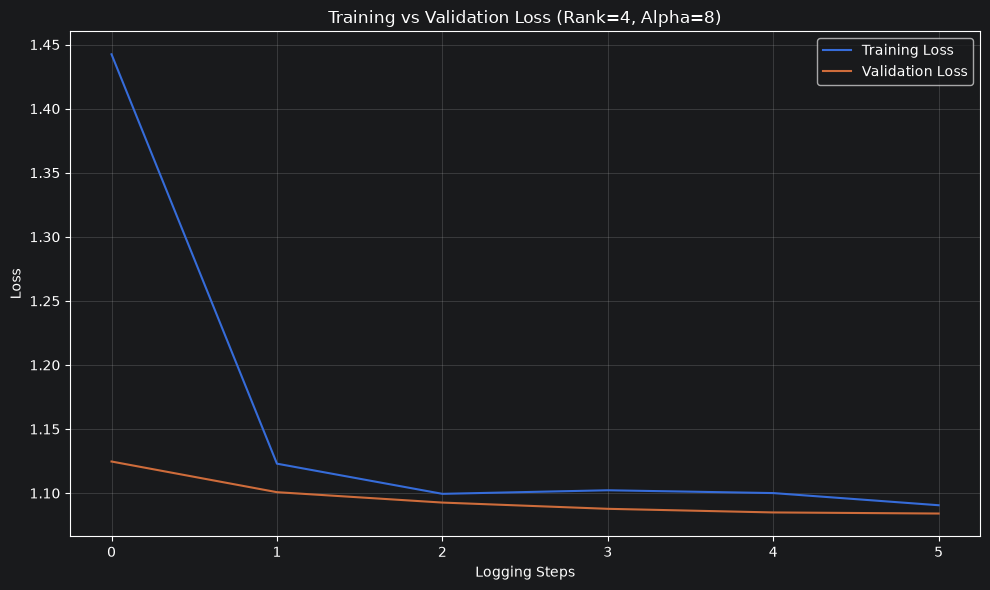

In [3]:
run_training_experiment(4, 8, "./test1/r4a8")

In [6]:
run_training_experiment(4, 8, "./test2/r4a8")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 434/434 [00:09<00:00, 46.61it/s]
C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\transformers\modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
C:\Users\Anthony\Downloads\llm_qlora_training\.venv\Lib\site-packages\transformers\modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


trainable params: 1,843,200 || all params: 3,087,781,888 || trainable%: 0.0597


Map: 100%|██████████| 50000/50000 [02:25<00:00, 344.22 examples/s]

Training... Epoch 1/1 | Batch 1/11218



[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Training... Epoch 1/1 | Batch 2/11218
Training... Epoch 1/1 | Batch 3/11218
Training... Epoch 1/1 | Batch 4/11218
Training... Epoch 1/1 | Batch 5/11218
Training... Epoch 1/1 | Batch 6/11218
Training... Epoch 1/1 | Batch 7/11218
Training... Epoch 1/1 | Batch 8/11218
Training... Epoch 1/1 | Batch 9/11218
Training... Epoch 1/1 | Batch 10/11218
Training... Epoch 1/1 | Batch 11/11218
Training... Epoch 1/1 | Batch 12/11218
Training... Epoch 1/1 | Batch 13/11218
Training... Epoch 1/1 | Batch 14/11218
Training... Epoch 1/1 | Batch 15/11218
Training... Epoch 1/1 | Batch 16/11218
Training... Epoch 1/1 | Batch 17/11218
Training... Epoch 1/1 | Batch 18/11218
Training... Epoch 1/1 | Batch 19/11218
Training... Epoch 1/1 | Batch 20/11218
Training... Epoch 1/1 | Batch 21/11218
Training... Epoch 1/1 | Batch 22/11218
Training... Epoch 1/1 | Batch 23/11218
Training... Epoch 1/1 | Batch 24/11218
Training... Epoch 1/1 | Batch 25/11218
Training... Epoch 1/1 | Batch 26/11218
Training... Epoch 1/1 | Batch 27/

KeyboardInterrupt: 

In [14]:
dataset = Dataset.from_list(list(load_dataset(
    dataset_name,
    split="train",
    streaming=True
).take(1000)))
dataset.column_names, dataset[0]

(['source', 'problem', 'solution', 'messages'],
 {'source': 'synthetic_math',
  'problem': 'Consider the terms of an arithmetic sequence: $-\\frac{1}{3}, y+2, 4y, \\ldots$. Solve for $y$.',
  'solution': 'For an arithmetic sequence, the difference between consecutive terms must be equal. Therefore, we can set up the following equations based on the sequence given:\n\\[ (y + 2) - \\left(-\\frac{1}{3}\\right) = 4y - (y+2) \\]\n\nSimplify and solve these equations:\n\\[ y + 2 + \\frac{1}{3} = 4y - y - 2 \\]\n\\[ y + \\frac{7}{3} = 3y - 2 \\]\n\\[ \\frac{7}{3} + 2 = 3y - y \\]\n\\[ \\frac{13}{3} = 2y \\]\n\\[ y = \\frac{13}{6} \\]\n\nThus, the value of $y$ that satisfies the given arithmetic sequence is $\\boxed{\\frac{13}{6}}$.',
  'messages': [{'content': 'Consider the terms of an arithmetic sequence: $-\\frac{1}{3}, y+2, 4y, \\ldots$. Solve for $y$.',
    'role': 'user'},
   {'content': 'For an arithmetic sequence, the difference between consecutive terms must be equal. Therefore, we ca